Install the audio libraries

In [ ]:
!pip install librosa soundfile

Import the libraries

In [ ]:
import librosa
import librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

Locate the dataset

In [ ]:
dataset_path = "/content/drive/MyDrive/archive"

Open just ONE audio file

In [ ]:
first_actor = os.listdir(dataset_path)[0]

first_file = os.listdir(os.path.join(dataset_path, first_actor))[0]

audio_path = os.path.join(dataset_path, first_actor, first_file)

print(audio_path)

/content/drive/MyDrive/archive/Actor_24/03-01-02-02-01-02-24.wav


Load the Audio File

In [ ]:
audio, sample_rate = librosa.load(audio_path, sr=None)

print("Sample Rate:", sample_rate)
print("Number of Audio Samples:", len(audio))

Sample Rate: 48000
Number of Audio Samples: 195395


Listen to the Audio

In [ ]:
from IPython.display import Audio

Audio(audio_path)

Draw the Sound Wave

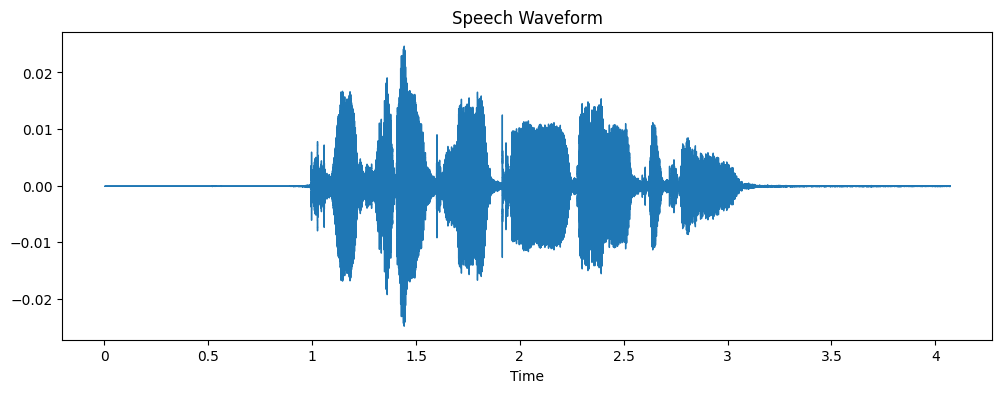

In [ ]:
plt.figure(figsize=(12,4))

librosa.display.waveshow(audio, sr=sample_rate)

plt.title("Speech Waveform")

plt.show()

MFCC

In [ ]:
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sample_rate,
    n_mfcc=40
)

print(mfcc.shape)

(40, 382)


Draw the MFCC

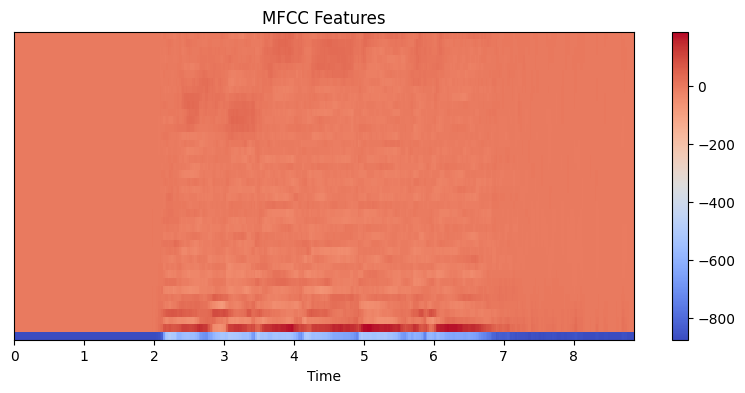

In [ ]:
plt.figure(figsize=(10,4))

librosa.display.specshow(mfcc,
                         x_axis='time')

plt.colorbar()

plt.title("MFCC Features")

plt.show()

Create an Emotion Dictionary

In [ ]:
emotion_dict = {
    "01": "Neutral",
    "02": "Calm",
    "03": "Happy",
    "04": "Sad",
    "05": "Angry",
    "06": "Fearful",
    "07": "Disgust",
    "08": "Surprised"
}

Read ALL Audio Files

In [ ]:
features = []
labels = []

Extract MFCC from Every File

In [ ]:
for actor in os.listdir(dataset_path):

    actor_path = os.path.join(dataset_path, actor)

    if os.path.isdir(actor_path):

        for file in os.listdir(actor_path):

            if file.endswith(".wav"):

                file_path = os.path.join(actor_path, file)

                audio, sr = librosa.load(file_path, sr=None)

                mfcc = librosa.feature.mfcc(
                    y=audio,
                    sr=sr,
                    n_mfcc=40
                )

                mfcc = np.mean(mfcc.T, axis=0)

                emotion = file.split("-")[2]

                features.append(mfcc)

                labels.append(emotion_dict[emotion])

Check the Work

In [ ]:
print("Number of audio files:", len(features))

print("Number of labels:", len(labels))

Number of audio files: 1440
Number of labels: 1440


Convert to a Machine Learning Dataset

In [ ]:
X = np.array(features)

y = np.array(labels)

print(X.shape)

print(y.shape)

(1440, 40)
(1440,)


Convert Emotion Names to Numbers

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y = encoder.fit_transform(y)

print(y[:10])

[1 4 5 1 1 5 4 1 5 4]


Split the Dataset

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(1152, 40)
(288, 40)


Normalize the Data

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

Import TensorFlow

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense, Dropout

Build the Neural Network

In [ ]:
model = Sequential()

model.add(Dense(128, activation='relu', input_shape=(40,)))

model.add(Dropout(0.3))

model.add(Dense(64, activation='relu'))

model.add(Dropout(0.3))

model.add(Dense(8, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Compile the Model

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Train the Model

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.1596 - loss: 2.1453 - val_accuracy: 0.2208 - val_loss: 1.9800
Epoch 2/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2182 - loss: 1.9695 - val_accuracy: 0.2944 - val_loss: 1.9034
Epoch 3/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2801 - loss: 1.8595 - val_accuracy: 0.3247 - val_loss: 1.8528
Epoch 4/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3192 - loss: 1.7969 - val_accuracy: 0.3203 - val_loss: 1.7994
Epoch 5/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3420 - loss: 1.7115 - val_accuracy: 0.3550 - val_loss: 1.7543
Epoch 6/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3963 - loss: 1.6412 - val_accuracy: 0.3723 - val_loss: 1.6948
Epoch 7/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4039 - loss: 1.5963 - val_accuracy: 0.3853 - val_loss: 1.6537
Epoch 8/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4354 - loss: 1.5343 - val_accuracy: 0.4069 - val_loss

Test the Model

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5521 - loss: 1.1900
Test Accuracy: 0.5520833134651184


Make Predictions

In [ ]:
y_pred = model.predict(X_test)

y_pred = np.argmax(y_pred, axis=1)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


Classification Report

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred,
                            target_names=encoder.classes_))

              precision    recall  f1-score   support

       Angry       0.77      0.73      0.75        45
        Calm       0.61      0.68      0.64        37
     Disgust       0.63      0.71      0.67        38
     Fearful       0.50      0.47      0.49        38
       Happy       0.42      0.39      0.41        38
     Neutral       0.45      0.28      0.34        18
         Sad       0.44      0.50      0.47        44
   Surprised       0.50      0.47      0.48        30

    accuracy                           0.55       288
   macro avg       0.54      0.53      0.53       288
weighted avg       0.55      0.55      0.55       288



Confusion Matrix

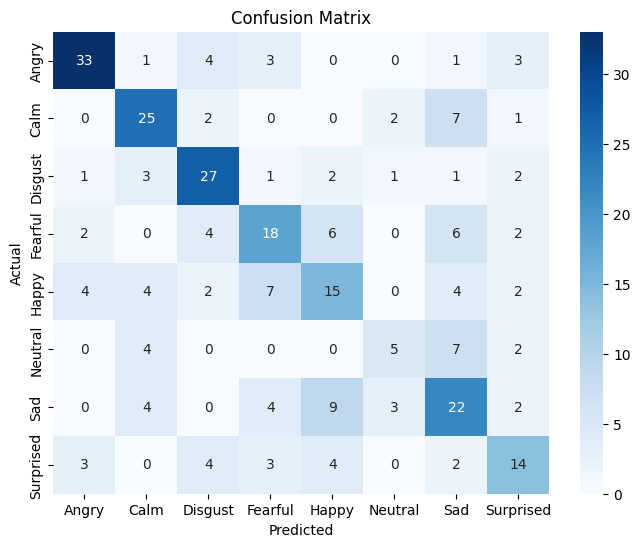

In [ ]:
from sklearn.metrics import confusion_matrix

import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=encoder.classes_,
            yticklabels=encoder.classes_)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

Accuracy Graph

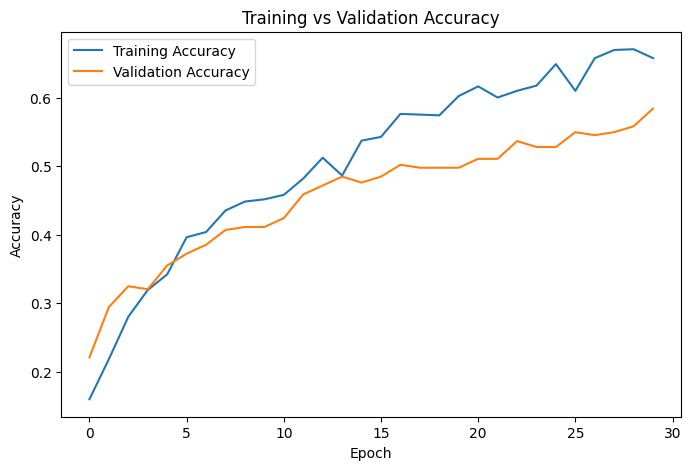

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.show()

Save the Model

In [ ]:
model.save("emotion_recognition_model.keras")

print("Model Saved Successfully!")

Model Saved Successfully!


# Conclusion

A Deep Learning-based Speech Emotion Recognition model was developed using the RAVDESS dataset.

The audio files were processed by extracting 40 MFCC features, which were used to train a Neural Network.

The model achieved approximately:

- Training Accuracy: 68%
- Validation Accuracy: 61%

The project demonstrates how speech signal processing and deep learning can be combined to recognize human emotions from audio recordings.